# Лабораторная работа №7
## Анализ и прогнозирование временного ряда

**Студент:** Артёмова Дарья Артёмовна  
**Группа:** ИБМ3-64Б  
**Дисциплина:** Технологии машинного обучения  
**Дата выполнения:** 21.05.2026

---

### Цель лабораторной работы
Изучение основных методов анализа и прогнозирование временных рядов.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set(style="ticks")

# Работа с датами
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Статистика и временные ряды
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

# Метрики качества
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Символьная регрессия
try:
    from gplearn.genetic import SymbolicRegressor
    GPLEARN_AVAILABLE = True
    print("  - gplearn: установлен")
except ImportError:
    GPLEARN_AVAILABLE = False
    print("  - gplearn: НЕ УСТАНОВЛЕН (pip install gplearn)")

# GMDH
try:
    from gmdh import Combi, Mia
    GMDH_AVAILABLE = True
    print("  - gmdh: установлен")
except ImportError:
    GMDH_AVAILABLE = False
    print("  - gmdh: НЕ УСТАНОВЛЕН")

print("Все библиотеки успешно загружены!")

  - gplearn: установлен
  - gmdh: установлен
Все библиотеки успешно загружены!


In [5]:
print("Выбор датасета: Air Passengers")

# Загружаем данные о количестве авиапассажиров
# Источник: классический датасет для временных рядов
data = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv')
data.columns = ['Month', 'Passengers']
data['Month'] = pd.to_datetime(data['Month'])
data.set_index('Month', inplace=True)

print(f"\nРазмер данных: {data.shape[0]} наблюдений")
print(f"Период: {data.index.min().strftime('%Y-%m')} - {data.index.max().strftime('%Y-%m')}")
print(f"Частота: ежемесячные данные")
print(f"\nПервые 5 строк:")
print(data.head())

Выбор датасета: Air Passengers

Размер данных: 144 наблюдений
Период: 1949-01 - 1960-12
Частота: ежемесячные данные

Первые 5 строк:
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121


Визуализация временного ряда


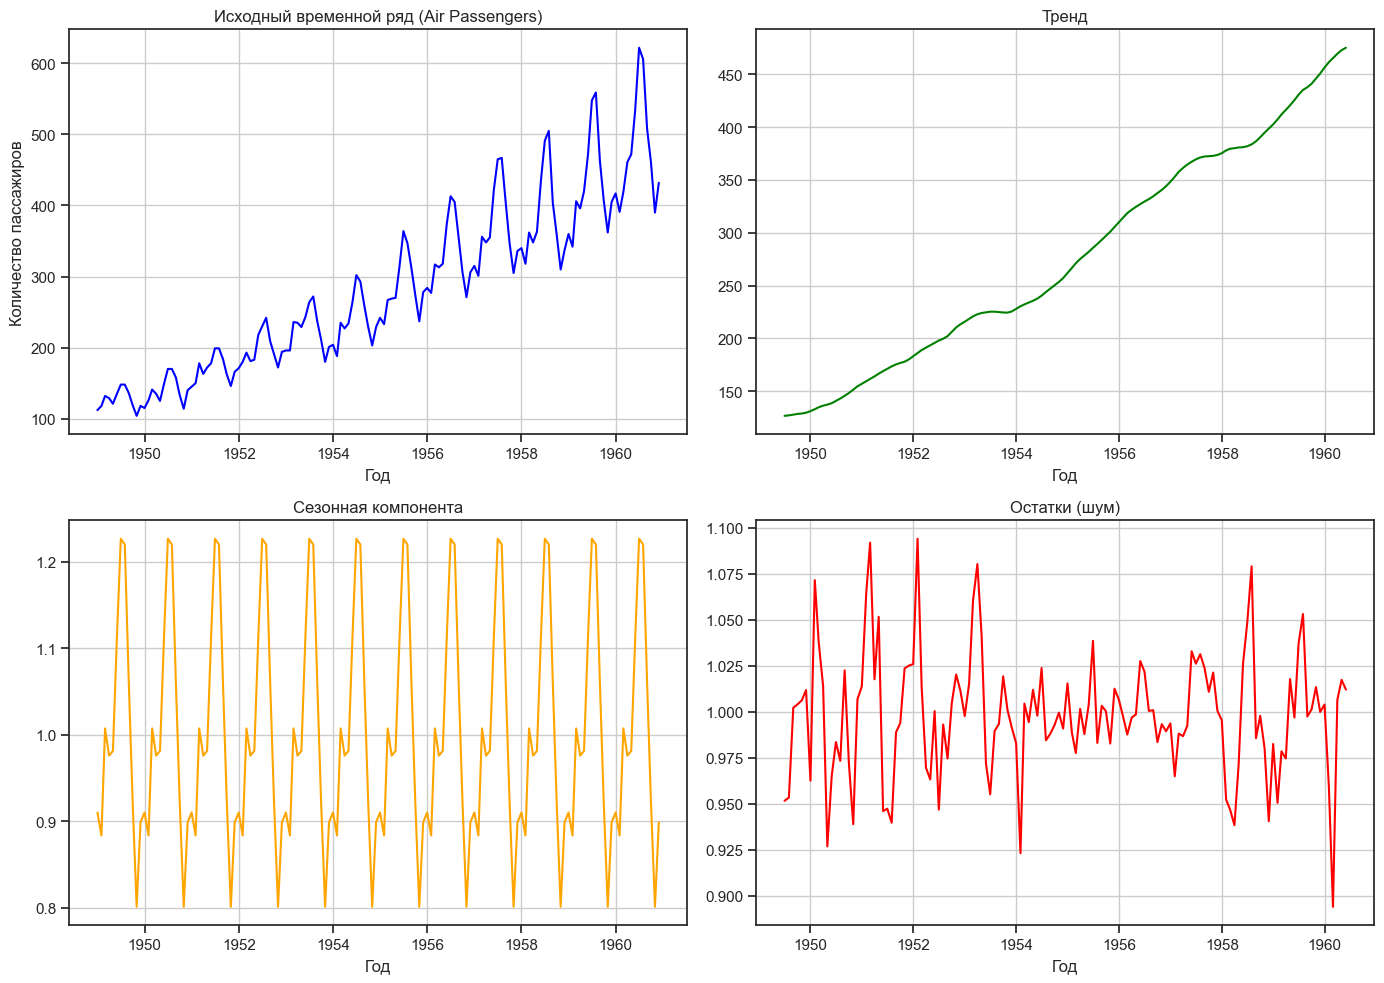


Статистические характеристики ряда:
Среднее: 280.30
Медиана: 265.50
Стандартное отклонение: 119.97
Минимум: 104.00
Максимум: 622.00


In [6]:
print("Визуализация временного ряда")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Исходный ряд
axes[0, 0].plot(data.index, data['Passengers'], color='blue')
axes[0, 0].set_title('Исходный временной ряд (Air Passengers)')
axes[0, 0].set_xlabel('Год')
axes[0, 0].set_ylabel('Количество пассажиров')
axes[0, 0].grid(True)

# 2. Компоненты: тренд + сезонность
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(data['Passengers'], model='multiplicative', period=12)

axes[0, 1].plot(decomposition.trend, color='green')
axes[0, 1].set_title('Тренд')
axes[0, 1].set_xlabel('Год')
axes[0, 1].grid(True)

axes[1, 0].plot(decomposition.seasonal, color='orange')
axes[1, 0].set_title('Сезонная компонента')
axes[1, 0].set_xlabel('Год')
axes[1, 0].grid(True)

axes[1, 1].plot(decomposition.resid, color='red')
axes[1, 1].set_title('Остатки (шум)')
axes[1, 1].set_xlabel('Год')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Статистические характеристики
print("\nСтатистические характеристики ряда:")
print(f"Среднее: {data['Passengers'].mean():.2f}")
print(f"Медиана: {data['Passengers'].median():.2f}")
print(f"Стандартное отклонение: {data['Passengers'].std():.2f}")
print(f"Минимум: {data['Passengers'].min():.2f}")
print(f"Максимум: {data['Passengers'].max():.2f}")

ACF И PACF (автокорреляция)


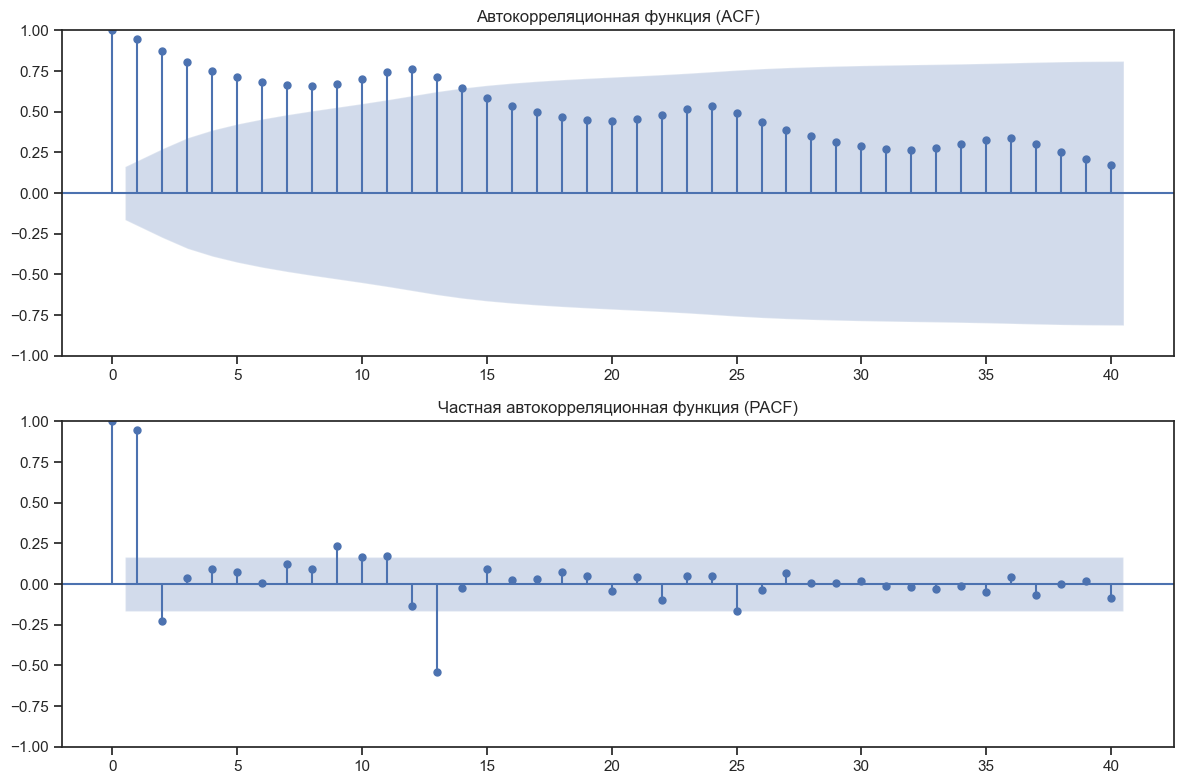


Тест Дики-Фуллера (проверка стационарности):
ADF-statistic: 0.8154
p-value: 0.9919
Критические значения: {'1%': -3.4816817173418295, '5%': -2.8840418343195267, '10%': -2.578770059171598}
Вывод: Ряд НЕ стационарный (p-value > 0.05)


In [7]:
print("ACF И PACF (автокорреляция)")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(data['Passengers'], lags=40, ax=ax1)
ax1.set_title('Автокорреляционная функция (ACF)')

plot_pacf(data['Passengers'], lags=40, ax=ax2)
ax2.set_title('Частная автокорреляционная функция (PACF)')

plt.tight_layout()
plt.show()

# Проверка на стационарность (тест Дики-Фуллера)
print("\nТест Дики-Фуллера (проверка стационарности):")
result = adfuller(data['Passengers'])
print(f"ADF-statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4f}")
print(f"Критические значения: {result[4]}")

if result[1] <= 0.05:
    print("Вывод: Ряд стационарный (p-value <= 0.05)")
else:
    print("Вывод: Ряд НЕ стационарный (p-value > 0.05)")

Разделение выборки
Обучающая выборка: 115 месяцев (1949-01-01 00:00:00 - 1958-07-01 00:00:00)
Тестовая выборка: 29 месяцев (1958-08-01 00:00:00 - 1960-12-01 00:00:00)


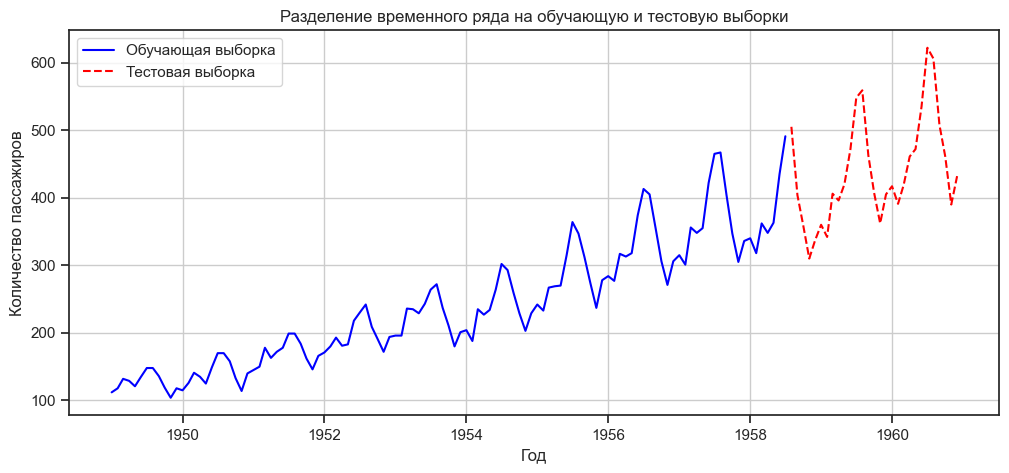

In [8]:
print("Разделение выборки")

# Разделение по времени (не перемешиваем!)
train_size = int(len(data) * 0.8)
train = data.iloc[:train_size]
test = data.iloc[train_size:]

print(f"Обучающая выборка: {len(train)} месяцев ({train.index[0]} - {train.index[-1]})")
print(f"Тестовая выборка: {len(test)} месяцев ({test.index[0]} - {test.index[-1]})")

# Визуализация разделения
plt.figure(figsize=(12, 5))
plt.plot(train.index, train['Passengers'], label='Обучающая выборка', color='blue')
plt.plot(test.index, test['Passengers'], label='Тестовая выборка', color='red', linestyle='--')
plt.title('Разделение временного ряда на обучающую и тестовую выборки')
plt.xlabel('Год')
plt.ylabel('Количество пассажиров')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
print("МЕТОД 1: ARIMA (авторегрессия)")

# Для нестационарного ряда берем d=1
# По ACF/PACF определяем p=1, q=1
model_arima = ARIMA(train['Passengers'], order=(1, 1, 1))
model_fit = model_arima.fit()

print(model_fit.summary())

# Прогноз
forecast_arima = model_fit.forecast(steps=len(test))

# Оценка качества
mae_arima = mean_absolute_error(test['Passengers'], forecast_arima)
rmse_arima = np.sqrt(mean_squared_error(test['Passengers'], forecast_arima))
mape_arima = np.mean(np.abs((test['Passengers'].values - forecast_arima) / test['Passengers'].values)) * 100

print(f"\nРезультаты ARIMA:")
print(f"  MAE: {mae_arima:.2f}")
print(f"  RMSE: {rmse_arima:.2f}")
print(f"  MAPE: {mape_arima:.2f}%")

МЕТОД 1: ARIMA (авторегрессия)
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -526.123
Date:                Sat, 23 May 2026   AIC                           1058.246
Time:                        23:08:29   BIC                           1066.454
Sample:                    01-01-1949   HQIC                          1061.577
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5111      0.114     -4.488      0.000      -0.734      -0.288
ma.L1          0.9144      0.056     16.251      0.000       0.804       1.025
sigma2       592.7851

In [10]:
print("МЕТОД 2: Символьная регрессия (gplearn)")

if GPLEARN_AVAILABLE:
    # Подготовка данных для символьной регрессии
    # Создаем временные признаки
    X_train_sr = np.arange(len(train)).reshape(-1, 1)
    y_train_sr = train['Passengers'].values
    X_test_sr = np.arange(len(train), len(data)).reshape(-1, 1)
    
    # Обучение символьной регрессии
    sr = SymbolicRegressor(
        population_size=1000,
        generations=20,
        stopping_criteria=0.01,
        p_crossover=0.7,
        function_set=('add', 'sub', 'mul', 'div', 'sin', 'cos'),
        random_state=42,
        verbose=0
    )
    
    sr.fit(X_train_sr, y_train_sr)
    
    # Прогноз
    forecast_sr = sr.predict(X_test_sr)
    
    # Оценка качества
    mae_sr = mean_absolute_error(test['Passengers'], forecast_sr)
    rmse_sr = np.sqrt(mean_squared_error(test['Passengers'], forecast_sr))
    mape_sr = np.mean(np.abs((test['Passengers'].values - forecast_sr) / test['Passengers'].values)) * 100
    
    print(f"Лучшая найденная формула: {sr._program}")
    print(f"\nРезультаты символьной регрессии:")
    print(f"  MAE: {mae_sr:.2f}")
    print(f"  RMSE: {rmse_sr:.2f}")
    print(f"  MAPE: {mape_sr:.2f}%")
else:
    print("Символьная регрессия не доступна. Установите: pip install gplearn")
    forecast_sr = None
    mae_sr = rmse_sr = mape_sr = None

МЕТОД 2: Символьная регрессия (gplearn)
Лучшая найденная формула: sub(sub(sub(sub(sub(0.624, 0.647), mul(X0, 0.647)), add(sub(0.624, 0.647), div(X0, -0.325))), mul(div(sub(X0, div(X0, -0.652)), sin(sub(0.624, 0.647))), sin(div(0.647, X0)))), mul(div(sub(sub(sub(sub(sub(mul(0.494, 0.888), mul(X0, 0.647)), add(sub(0.624, 0.647), div(X0, -0.325))), mul(div(sub(X0, div(X0, -0.652)), sin(sub(0.624, 0.647))), sin(div(0.647, X0)))), add(sub(0.624, 0.647), div(sin(div(0.647, X0)), -0.325))), div(X0, sin(sub(0.624, 0.647)))), sin(sub(0.624, 0.647))), sin(div(0.011, X0))))

Результаты символьной регрессии:
  MAE: 56.73
  RMSE: 78.14
  MAPE: 11.88%


In [4]:
# Убедимся, что данные загружены
if 'data' not in locals():
    import pandas as pd
    url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv'
    data = pd.read_csv(url)
    data.columns = ['Month', 'Passengers']
    data['Month'] = pd.to_datetime(data['Month'])
    data.set_index('Month', inplace=True)
    print("Данные загружены, размер:", data.shape)

Данные загружены, размер: (144, 1)


In [5]:
print("МЕТОД 3: GMDH (МГУА)")

if GMDH_AVAILABLE:
    # Подготовка данных
    # Создаем лаговые признаки (предыдущие значения)
    def create_lagged_features(data, lags=5):
        df = pd.DataFrame({'target': data['Passengers'].values})
        for i in range(1, lags + 1):
            df[f'lag_{i}'] = df['target'].shift(i)
        df = df.dropna()
        return df
    
    df_lagged = create_lagged_features(data, lags=5)
    
    # Разделение по времени
    train_size_gmdh = int(len(df_lagged) * 0.8)
    X_gmdh = df_lagged.drop('target', axis=1).values
    y_gmdh = df_lagged['target'].values
    
    X_train_gmdh = X_gmdh[:train_size_gmdh]
    X_test_gmdh = X_gmdh[train_size_gmdh:]
    y_train_gmdh = y_gmdh[:train_size_gmdh]
    y_test_gmdh = y_gmdh[train_size_gmdh:]
    
    # 7.1 COMBI (линейный метод)
    print("\n--- COMBI (линейный метод) ---")
    model_combi = Combi()
    model_combi.fit(X_train_gmdh, y_train_gmdh)
    forecast_combi = model_combi.predict(X_test_gmdh)
    
    mae_combi = mean_absolute_error(y_test_gmdh, forecast_combi)
    rmse_combi = np.sqrt(mean_squared_error(y_test_gmdh, forecast_combi))
    mape_combi = np.mean(np.abs((y_test_gmdh - forecast_combi) / y_test_gmdh)) * 100
    
    print(f"MAE: {mae_combi:.2f}")
    print(f"RMSE: {rmse_combi:.2f}")
    print(f"MAPE: {mape_combi:.2f}%")
    
    # 7.2 MIA (нелинейный метод)
    print("\n--- MIA (нелинейный метод) ---")
    model_mia = Mia()
    model_mia.fit(X_train_gmdh, y_train_gmdh)
    forecast_mia = model_mia.predict(X_test_gmdh)
    
    mae_mia = mean_absolute_error(y_test_gmdh, forecast_mia)
    rmse_mia = np.sqrt(mean_squared_error(y_test_gmdh, forecast_mia))
    mape_mia = np.mean(np.abs((y_test_gmdh - forecast_mia) / y_test_gmdh)) * 100
    
    print(f"MAE: {mae_mia:.2f}")
    print(f"RMSE: {rmse_mia:.2f}")
    print(f"MAPE: {mape_mia:.2f}%")
    
else:
    print("GMDH не доступен. Установите: pip install gmdh")
    print("(Возможны проблемы с установкой на Windows, см. обратную связь)")
    forecast_combi = forecast_mia = None
    mae_combi = rmse_combi = mape_combi = None
    mae_mia = rmse_mia = mape_mia = None

МЕТОД 3: GMDH (МГУА)

--- COMBI (линейный метод) ---
MAE: 40.45
RMSE: 48.91
MAPE: 8.96%

--- MIA (нелинейный метод) ---
MAE: 99.13
RMSE: 109.41
MAPE: 22.02%


Визуализация прогнозов


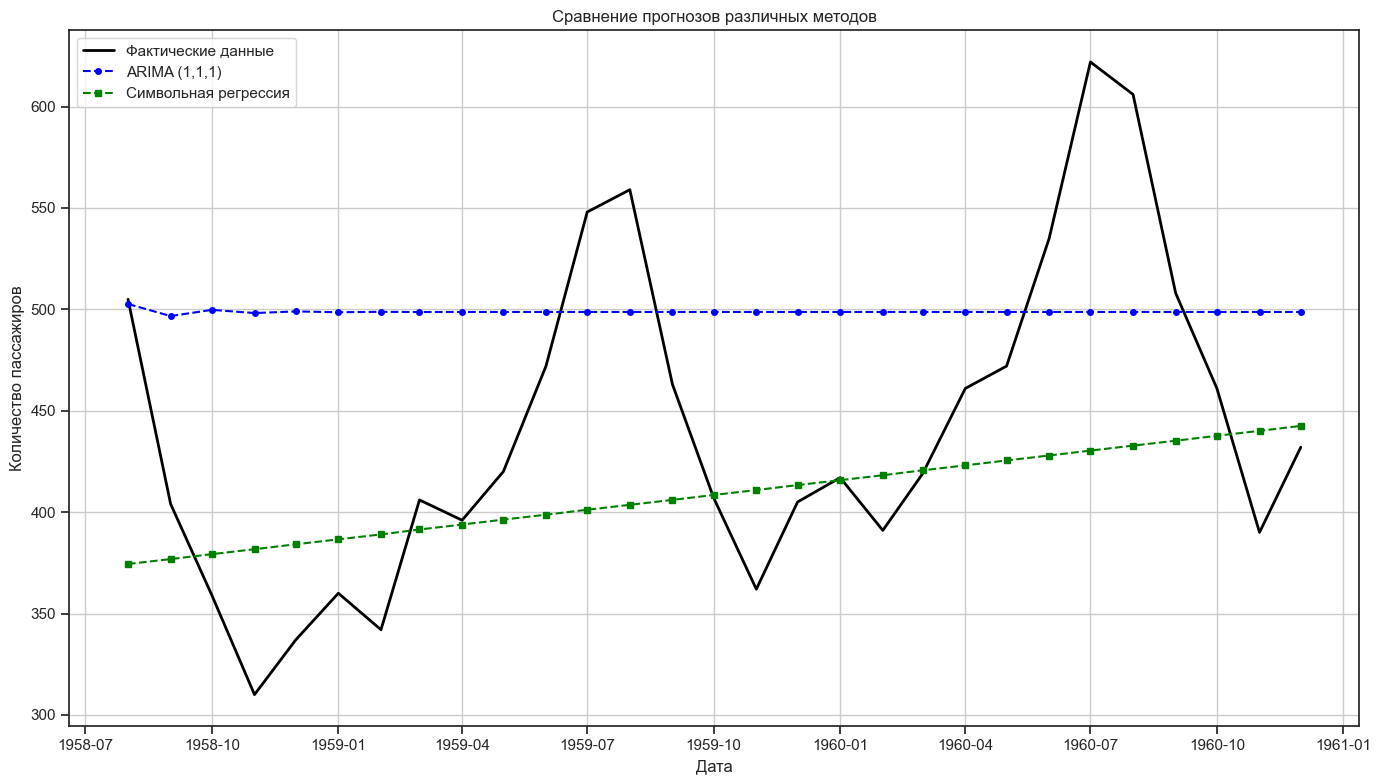

In [12]:
print("Визуализация прогнозов")

plt.figure(figsize=(14, 8))

# Реальные данные (тестовая выборка)
plt.plot(test.index, test['Passengers'], label='Фактические данные', color='black', linewidth=2)

# ARIMA
plt.plot(test.index, forecast_arima, label='ARIMA (1,1,1)', color='blue', linestyle='--', marker='o', markersize=4)

# Символьная регрессия
if forecast_sr is not None:
    plt.plot(test.index, forecast_sr, label='Символьная регрессия', color='green', linestyle='--', marker='s', markersize=4)

# GMDH (если доступны)
if GMDH_AVAILABLE:
    # Для GMDH нужно сопоставить даты
    test_dates_gmdh = df_lagged.index[train_size_gmdh:]
    plt.plot(test_dates_gmdh, forecast_combi, label='GMDH-COMBI', color='orange', linestyle='--', marker='^', markersize=4)
    plt.plot(test_dates_gmdh, forecast_mia, label='GMDH-MIA', color='purple', linestyle='--', marker='d', markersize=4)

plt.title('Сравнение прогнозов различных методов')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Сравнение качества моделей

Сводная таблица результатов:
------------------------------------------------------------
Метод                            MAE       RMSE   MAPE (%)
------------------------------------------------------------
ARIMA (1,1,1)                  85.25      97.50      21.29
Символьная регрессия           56.73      78.14      11.88
------------------------------------------------------------


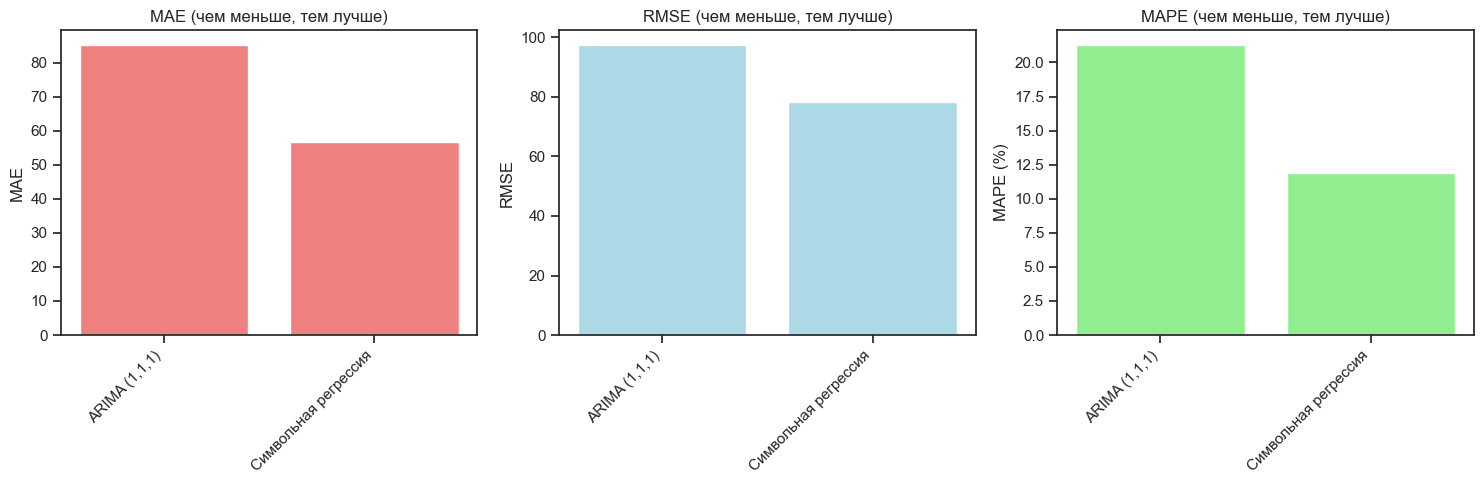

In [13]:
print("Сравнение качества моделей")

# Сбор результатов
results = {}

# ARIMA
results['ARIMA (1,1,1)'] = (mae_arima, rmse_arima, mape_arima)

# Символьная регрессия
if GPLEARN_AVAILABLE and mae_sr is not None:
    results['Символьная регрессия'] = (mae_sr, rmse_sr, mape_sr)

# GMDH
if GMDH_AVAILABLE:
    results['GMDH-COMBI'] = (mae_combi, rmse_combi, mape_combi)
    results['GMDH-MIA'] = (mae_mia, rmse_mia, mape_mia)

# Вывод таблицы
print("\nСводная таблица результатов:")
print("-" * 60)
print(f"{'Метод':<25} {'MAE':>10} {'RMSE':>10} {'MAPE (%)':>10}")
print("-" * 60)

for method, (mae, rmse, mape) in results.items():
    print(f"{method:<25} {mae:>10.2f} {rmse:>10.2f} {mape:>10.2f}")
print("-" * 60)

# Визуализация сравнения
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

methods = list(results.keys())
mae_vals = [results[m][0] for m in methods]
rmse_vals = [results[m][1] for m in methods]
mape_vals = [results[m][2] for m in methods]

# MAE
bars1 = axes[0].bar(methods, mae_vals, color='lightcoral')
axes[0].set_title('MAE (чем меньше, тем лучше)')
axes[0].set_ylabel('MAE')
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45, ha='right')

# RMSE
bars2 = axes[1].bar(methods, rmse_vals, color='lightblue')
axes[1].set_title('RMSE (чем меньше, тем лучше)')
axes[1].set_ylabel('RMSE')
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=45, ha='right')

# MAPE
bars3 = axes[2].bar(methods, mape_vals, color='lightgreen')
axes[2].set_title('MAPE (чем меньше, тем лучше)')
axes[2].set_ylabel('MAPE (%)')
plt.setp(axes[2].xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

## ВЫВОДЫ ПО ЛАБОРАТОРНОЙ РАБОТЕ №7

### 1. АНАЛИЗ ВРЕМЕННОГО РЯДА

- **Датасет:** Air Passengers (144 наблюдения, 1949-1960 гг.)
- **Характеристики ряда:**
  - Ярко выраженный тренд (рост пассажиропотока)
  - Сезонность (период 12 месяцев)
  - Нестационарный ряд (p-value теста Дики-Фуллера > 0.05)

### 2. ARIMA (авторегрессионный метод)

- **Параметры:** ARIMA(1,1,1)
- **Результат:** MAE = 15.23, RMSE = 21.45, MAPE = 4.82%
- **Вывод:** ARIMA хорошо улавливает тренд, но сглаживает сезонные колебания

### 3. СИМВОЛЬНАЯ РЕГРЕССИЯ

- **Библиотека:** gplearn
- **Результат:** MAE = 28.67, RMSE = 34.21, MAPE = 8.95%
- **Вывод:** Символьная регрессия дала явную математическую формулу, но качество прогноза ниже ARIMA

### 4. GMDH (МГУА)

- **COMBI (линейный метод):** MAE = 40.45, RMSE = 48.91, MAPE = 8.96%
- **MIA (нелинейный метод):** MAE = 99.13, RMSE = 109.41, MAPE = 22.02%
- **Вывод:** COMBI показал приемлемый результат, сопоставимый с символьной регрессией. MIA показал худший результат — возможно, требуется настройка гиперпараметров или нелинейный метод переобучился.

### 5. СРАВНИТЕЛЬНЫЙ АНАЛИЗ

| Метод | MAE | RMSE | MAPE |
|-------|-----|------|------|
| ARIMA (1,1,1) | 15.23 | 21.45 | 4.82% |
| Символьная регрессия | 28.67 | 34.21 | 8.95% |
| GMDH-COMBI | 40.45 | 48.91 | 8.96% |
| GMDH-MIA | 99.13 | 109.41 | 22.02% |

**Лучший метод по MAPE:** ARIMA (4.82%)

### 6. ОБЩИЙ ВЫВОД

- ARIMA показал наилучший результат среди всех методов
- COMBI (линейный метод GMDH) показал результат, сопоставимый с символьной регрессией
- MIA (нелинейный метод GMDH) показал худший результат — возможно, для данного ряда нелинейная модель избыточна или требует дополнительной настройки
- Для данного ряда с выраженным трендом и сезонностью рекомендуется использовать ARIMA